### **Session 9 · Notebook 1 — The data, and why a plain RNN cannot translate**

Session 9 deck, *Working with RNN (II): machine translation*. Run in Colab with a GPU (Runtime → Change runtime type → T4 GPU).

**The ladder of this session** (one notebook per step, all on the same data and the same test set):

| Notebook | Model |
|---|---|
| **01** | **"aligned" LSTM: one Spanish word for each English word** |
| 02 | encoder–decoder with GRU (Cho et al., 2014) |
| 03 | encoder–decoder with LSTM |
| 04 | bidirectional LSTM encoder |
| 05 | Sutskever et al. (2014): deep LSTM, reversed source, beam search |

This notebook does two things:
1. **Downloads** the English–Spanish sentence pairs, cleans them and saves `data/pairs.tsv`
   with a fixed train / validation / test split. **The other four notebooks read this file.**
2. Trains the simplest possible "translator": an LSTM that reads the English sentence and outputs
   one Spanish word at each position. We will see why this idea is wrong.

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow info messages
import json, time, re, math, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops
print("Keras", keras.__version__, "| TensorFlow", tf.__version__,
      "| GPU:", tf.config.list_physical_devices("GPU"))
keras.utils.set_random_seed(42)
os.makedirs("results", exist_ok=True)

I0000 00:00:1792175338.485102    1616 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792175339.450737    1616 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras 3.12.3 | TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Parameters

In [2]:
DATA_DIR = "data"          # where Notebook 1 saved pairs.tsv (see the note above for Colab + Drive)
VOCAB = 15000              # words kept in each language (the rest become [UNK])
SRC_LEN = 12               # English: at most 10 words, padded to 12
TGT_LEN = 13               # Spanish: [start] + at most 10 words + [end], padded to 13
EMB = 256                  # size of the word vectors
BATCH = 64
EPOCHS = 20                # maximum; EarlyStopping usually stops earlier
QUICK = False              # True: a short trial run (few batches, 2 epochs) to check that the code works
MAX_WORDS = 10             # keep pairs with at most 10 words in each language
N_PAIRS = 60000            # pairs used in the course: 50,000 train, 5,000 validation, 5,000 test

**Colab tip.** Every Colab notebook runs on its own machine, so a file saved by Notebook 1 is not
visible from Notebook 2. To share the data, mount your Google Drive in every notebook and point
`DATA_DIR` to the same Drive folder:

```python
from google.colab import drive
drive.mount("/content/drive")
DATA_DIR = "/content/drive/MyDrive/DL26/session9/data"
```
(Or simply upload `data/pairs.tsv`, created by Notebook 1, to the `data/` folder of this notebook.)

## 2. Download the data

About 118,000 English–Spanish sentence pairs from the [Tatoeba project](https://tatoeba.org),
prepared by [ManyThings.org](https://www.manythings.org/anki/). TensorFlow hosts a copy (2.6 MB zip).
Each line is `English <TAB> Spanish`.

In [3]:
import zipfile, urllib.request
os.makedirs(DATA_DIR, exist_ok=True)
RAW = os.path.join(DATA_DIR, "spa.txt")
URLS = ["http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip",
        "https://www.manythings.org/anki/spa-eng.zip"]          # second copy, if the first fails
if not os.path.exists(RAW):
    for url in URLS:
        try:
            print("Downloading", url)
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as r, open("spa-eng.zip", "wb") as f:
                f.write(r.read())
            break
        except Exception as e:
            print("  failed:", e)
    with zipfile.ZipFile("spa-eng.zip") as z:
        name = [n for n in z.namelist() if n.endswith("spa.txt")][0]
        with z.open(name) as src, open(RAW, "wb") as dst:
            dst.write(src.read())
    os.remove("spa-eng.zip")
with open(RAW, encoding="utf-8") as f:
    lines = f.read().strip().split("\n")
print(f"{len(lines):,} lines")
for line in lines[:3] + lines[60000:60003] + lines[-2:]:
    print(line.split("\t")[:2])

118,964 lines
['Go.', 'Ve.']
['Go.', 'Vete.']
['Go.', 'Vaya.']
['Can you please leave me alone?', '¿Me puedes dejar sola, por favor?']
['Can you prove the allegations?', '¿Puede probar las acusaciones?']
['Can you prove the allegations?', '¿Puede probar las imputaciones?']
['Since there are usually multiple websites on any given topic, I usually just click the back button when I arrive on any webpage that has pop-up advertising. I just go to the next page found by Google and hope for something less irritating.', 'Como suele haber varias páginas web sobre cualquier tema, normalmente sólo le doy al botón de retroceso cuando entro en una página web que tiene anuncios en ventanas emergentes. Simplemente voy a la siguiente página encontrada por Google y espero encontrar algo menos irritante.']
['If you want to sound like a native speaker, you must be willing to practice saying the same sentence over and over in the same way that banjo players practice the same phrase over and over until the

## 3. Clean, filter and split

* lower case, remove punctuation (`¿ ¡ . , !` ...), but keep the accents: *está* and *esta* are different words
* keep pairs with at most 10 words in both languages (short sentences train fast)
* shuffle with a fixed seed and split **50,000 / 5,000 / 5,000**. Everybody gets the same test set.

In [4]:
def clean(text):
    text = text.lower().replace("’", "'")
    text = re.sub(r"[^\w\s']", " ", text)     # \w keeps letters with accents (á, é, ñ, ü)
    text = text.replace("'", "")               # don't -> dont, it's -> its
    return " ".join(text.split())

en = [clean(l.split("\t")[0]) for l in lines]
es = [clean(l.split("\t")[1]) for l in lines]
pairs = pd.DataFrame({"en": en, "es": es})
pairs = pairs[(pairs.en.str.split().str.len() <= MAX_WORDS) &
              (pairs.es.str.split().str.len() <= MAX_WORDS) & (pairs.en != "") & (pairs.es != "")]
print(f"{len(pairs):,} pairs with at most {MAX_WORDS} words")

pairs = pairs.sample(frac=1.0, random_state=42).head(N_PAIRS).reset_index(drop=True)
n_val = n_test = N_PAIRS // 12
pairs["split"] = ["test"] * n_test + ["val"] * n_val + ["train"] * (len(pairs) - n_test - n_val)
pairs.to_csv(os.path.join(DATA_DIR, "pairs.tsv"), sep="\t", index=False)
print("saved", os.path.join(DATA_DIR, "pairs.tsv"))
train = pairs[pairs.split == "train"]
val   = pairs[pairs.split == "val"]
test  = pairs[pairs.split == "test"]
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,} pairs")

108,409 pairs with at most 10 words
saved data/pairs.tsv
train 50,000 | val 5,000 | test 5,000 pairs


## 4. A first look

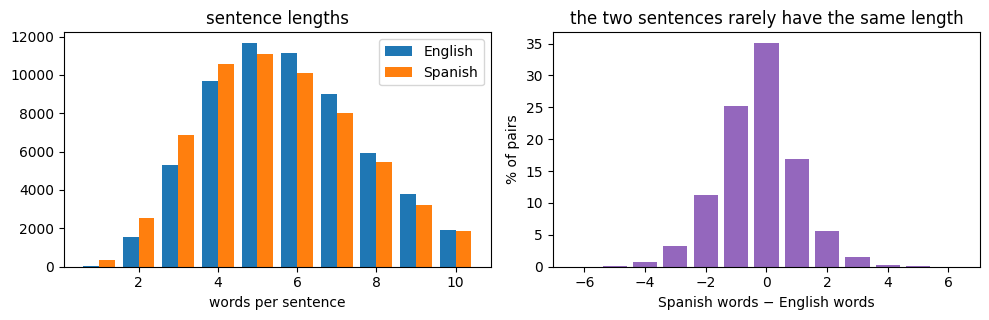

same number of words: 35% of the pairs


,en,es
25170,only a few people know how to do that,sólo unas cuantas personas saben cómo hacerlo
10935,im done with my homework,acabé mi tarea
43596,its very important,es muy importante
13970,i spoke to tom just a few minutes ago,hablé con tom hace unos pocos minutos
24883,she described him as a detective,ella lo describió como un detective
7581,they sat in the shade of a tree,se sentaron a la sombra de un árbol
1712,i was falsely accused,me acusaron injustamente
3004,he wears a bow tie every day,él se pone un corbatín todos los días
12834,i was an idiot,era un idiota
50176,wood burns easily,la madera se quema fácilmente


In [18]:
len_en = pairs.en.str.split().str.len()
len_es = pairs.es.str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].hist([len_en, len_es], bins=np.arange(0.5, 11.5), label=["English", "Spanish"])
ax[0].set_xlabel("words per sentence"); ax[0].set_title("sentence lengths"); ax[0].legend()
diff = (len_es - len_en).value_counts().sort_index()
ax[1].bar(diff.index, diff.values / len(pairs) * 100, color="tab:purple")
ax[1].set_xlabel("Spanish words − English words"); ax[1].set_ylabel("% of pairs")
ax[1].set_title("the two sentences rarely have the same length")
plt.tight_layout(); plt.savefig("results/nb1_lengths.png", dpi=600); plt.show()
print(f"same number of words: {(len_en == len_es).mean() * 100:.0f}% of the pairs")
pairs.sample(10, random_state=7)[["en", "es"]]

The same meaning needs a different number of words (*I'm hungry* → *tengo hambre*), and the order
changes (*the red car* → *el coche rojo*). Keep this in mind for the model below.

## 5. Text to numbers
`TextVectorization` builds a vocabulary of the 15,000 most frequent words of each language and turns every
sentence into a list of word indices, padded with zeros. Spanish sentences get two special words,
`[start]` and `[end]`.

In [6]:
def prepare_source(sentence):
    return sentence          # Notebook 5 will change this (reversed word order)

In [7]:
# Text -> integers. The text is already clean (lower case, no punctuation), so we only split on spaces.
# Index 0 is padding, index 1 is [UNK] (unknown word).
src_vec = layers.TextVectorization(VOCAB, standardize=None, output_sequence_length=SRC_LEN)
tgt_vec = layers.TextVectorization(VOCAB, standardize=None, output_sequence_length=TGT_LEN)
src_vec.adapt(train.en.map(prepare_source).values)        # vocabularies from the TRAINING set only
tgt_vec.adapt(("[start] " + train.es + " [end]").values)
src_words = src_vec.get_vocabulary()
tgt_words = tgt_vec.get_vocabulary()
START, END = tgt_words.index("[start]"), tgt_words.index("[end]")
N_SRC, N_TGT = len(src_words), len(tgt_words)            # real vocabulary sizes (at most VOCAB)
print("English vocabulary:", N_SRC, "| Spanish vocabulary:", N_TGT)
print("first Spanish words:", tgt_words[:12])

English vocabulary: 9368 | Spanish vocabulary: 15000
first Spanish words: ['', '[UNK]', np.str_('[start]'), np.str_('[end]'), np.str_('de'), np.str_('no'), np.str_('tom'), np.str_('a'), np.str_('que'), np.str_('la'), np.str_('el'), np.str_('es')]


## 6. The "aligned" LSTM

The many-to-many RNN of Session 7: read English word $t$, output Spanish word $t$.

```
 English :  i      am     hungry   ·      ·
 Spanish :  tengo  hambre [end]    ·      ·
```
The output at position $t$ can only use the English words $1..t$: it has not read the end of the sentence
yet. And the two sentences must be "aligned", word by word, which they are not.

In [8]:
def make_aligned_dataset(df, shuffle=False):
    src = src_vec(df.en.values)                                    # (n, 12)
    tgt = tgt_vec((df.es + " [end]").values)[:, :SRC_LEN]          # (n, 12): Spanish words + [end]
    ds = tf.data.Dataset.from_tensor_slices((src, tgt))
    if shuffle:
        ds = ds.shuffle(20000, seed=42)
    ds = ds.batch(BATCH)
    if QUICK:
        ds = ds.take(20)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = make_aligned_dataset(train, shuffle=True), make_aligned_dataset(val)

In [9]:
# Padding (index 0) must not count: the loss ignores class 0, and so does the accuracy.
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True, ignore_class=0)

class MaskedAccuracy(keras.metrics.Metric):
    """Fraction of real words (not padding) predicted correctly."""
    def __init__(self, name="masked_acc", **kwargs):
        super().__init__(name=name, **kwargs)
        self.correct = self.add_variable(shape=(), initializer="zeros", name="correct")
        self.total = self.add_variable(shape=(), initializer="zeros", name="total")

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = ops.cast(y_true, "int32")
        pred = ops.cast(ops.argmax(y_pred, axis=-1), "int32")
        mask = ops.cast(y_true != 0, "float32")
        self.correct.assign_add(ops.sum(ops.cast(pred == y_true, "float32") * mask))
        self.total.assign_add(ops.sum(mask))

    def result(self):
        return self.correct / ops.maximum(self.total, 1.0)

    def reset_state(self):
        self.correct.assign(0.0); self.total.assign(0.0)

In [10]:
NAME, MODEL_LABEL = "nb1", "aligned LSTM"
UNITS = 512
inputs = keras.Input(shape=(SRC_LEN,), dtype="int64", name="english")
x = layers.Embedding(N_SRC, EMB)(inputs)                 # no mask: it may output words after the English ends
x = layers.LSTM(UNITS, return_sequences=True)(x)         # one output vector per position
outputs = layers.Dense(N_TGT, name="next_word")(x)       # one score (logit) per Spanish word
model = keras.Model(inputs, outputs, name="aligned_lstm")
model.summary()

Model: "aligned_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ english (InputLayer)            │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 12, 256)        │     2,398,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 12, 512)        │     1,574,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ next_word (Dense)               │ (None, 12, 15000)      │     7,695,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,668,120 (44.51 MB)

 Trainable params: 11,668,120 (44.51 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),   # clipping: Session 7
              loss=loss_fn, metrics=[MaskedAccuracy()])
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]
t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=2 if QUICK else EPOCHS,
                    callbacks=callbacks, verbose=2)
minutes = (time.time() - t0) / 60
epochs_run = len(history.history["loss"])
print(f"training time: {minutes:.1f} min, {60 * minutes / epochs_run:.0f} s/epoch, {epochs_run} epochs")
model.save_weights(f"results/{NAME}.weights.h5")

Epoch 1/20
782/782 - 45s - 58ms/step - loss: 5.6955 - masked_acc: 0.2183 - val_loss: 4.8405 - val_masked_acc: 0.2734
Epoch 2/20
782/782 - 42s - 54ms/step - loss: 4.5630 - masked_acc: 0.3032 - val_loss: 4.2302 - val_masked_acc: 0.3235
Epoch 3/20
782/782 - 43s - 55ms/step - loss: 3.9037 - masked_acc: 0.3459 - val_loss: 3.9146 - val_masked_acc: 0.3484
Epoch 4/20
782/782 - 44s - 56ms/step - loss: 3.3917 - masked_acc: 0.3789 - val_loss: 3.7553 - val_masked_acc: 0.3615
Epoch 5/20
782/782 - 42s - 54ms/step - loss: 2.9740 - masked_acc: 0.4130 - val_loss: 3.6798 - val_masked_acc: 0.3716
Epoch 6/20
782/782 - 42s - 54ms/step - loss: 2.6375 - masked_acc: 0.4509 - val_loss: 3.6612 - val_masked_acc: 0.3744
Epoch 7/20
782/782 - 42s - 54ms/step - loss: 2.3738 - masked_acc: 0.4881 - val_loss: 3.6799 - val_masked_acc: 0.3751
Epoch 8/20
782/782 - 43s - 55ms/step - loss: 2.1676 - masked_acc: 0.5215 - val_loss: 3.7175 - val_masked_acc: 0.3767
Epoch 9/20
782/782 - 42s - 54ms/step - loss: 2.0016 - masked_acc

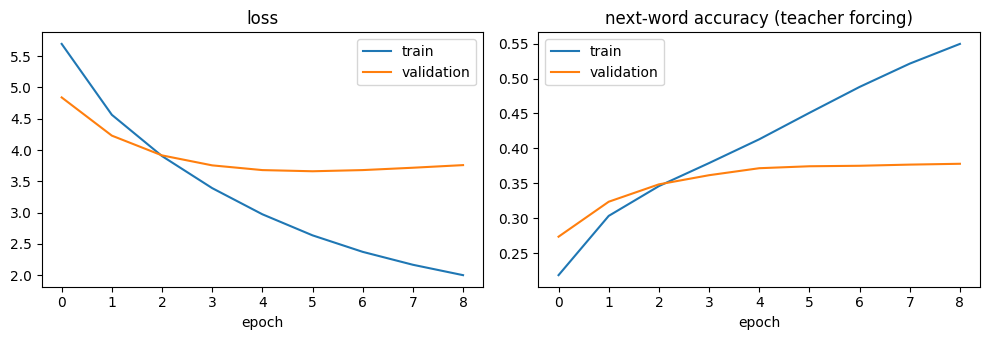

In [19]:
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["masked_acc"], label="train"); ax[1].plot(h["val_masked_acc"], label="validation")
ax[1].set_title("next-word accuracy (teacher forcing)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"results/{NAME}_curves.png", dpi=600); plt.show()

## 7. Translate
Translation is one pass: take the most likely Spanish word at every position and stop at `[end]`.

In [13]:
def to_words(ids):
    words = []
    for t in ids:
        if t == END or t == 0:
            break
        words.append(tgt_words[t])
    return " ".join(words)

def translate(sentences):
    logits = model.predict(src_vec(sentences), verbose=0, batch_size=512)
    return [to_words(row) for row in np.argmax(logits, axis=-1)]

In [14]:
def bleu(references, hypotheses, max_n=4):
    """Corpus BLEU (Papineni et al., 2002), 0-100, with one reference per sentence.
    Geometric mean of the 1- to 4-gram precisions, times a brevity penalty."""
    matches, totals = [0] * max_n, [0] * max_n
    ref_len = hyp_len = 0
    for ref, hyp in zip(references, hypotheses):
        ref, hyp = ref.split(), hyp.split()
        ref_len += len(ref); hyp_len += len(hyp)
        for n in range(1, max_n + 1):
            ref_ngrams = collections.Counter(tuple(ref[i:i + n]) for i in range(len(ref) - n + 1))
            hyp_ngrams = collections.Counter(tuple(hyp[i:i + n]) for i in range(len(hyp) - n + 1))
            matches[n - 1] += sum(min(c, ref_ngrams[g]) for g, c in hyp_ngrams.items())  # clipped counts
            totals[n - 1] += max(len(hyp) - n + 1, 0)
    # precision of each n-gram order; "+1" smoothing for n > 1 so that one order without matches
    # (e.g. no 4-grams in a 3-word sentence) does not make the whole score 0
    precisions = [matches[0] / max(totals[0], 1)] +                  [(m + 1) / (t + 1) for m, t in zip(matches[1:], totals[1:])]
    if precisions[0] == 0:
        return 0.0
    log_precision = sum(math.log(p) for p in precisions) / max_n
    brevity = min(1.0, math.exp(1 - ref_len / max(hyp_len, 1)))         # penalise short translations
    return 100 * brevity * math.exp(log_precision)

print("identical  :", round(bleu(["yo tengo hambre"], ["yo tengo hambre"]), 1))
print("one word   :", round(bleu(["el gato está en la mesa"], ["el perro está en la mesa"]), 1))

identical  : 100.0
one word   : 63.9


In [15]:
N_TEST = 500 if QUICK else len(test)
refs = list(test.es[:N_TEST])
t0 = time.time()
hyps = translate(list(test.en[:N_TEST]))
print(f"translated {N_TEST:,} test sentences in {time.time() - t0:.0f} s")
test_bleu = bleu(refs, hyps)
exact = np.mean([r == h for r, h in zip(refs, hyps)]) * 100
print(f"{NAME}: test BLEU = {test_bleu:.1f} | exact matches = {exact:.1f}%")

# BLEU by length of the English sentence
lengths = np.array([len(s.split()) for s in test.en[:N_TEST]])
BUCKETS = [(1, 3), (4, 5), (6, 7), (8, 10)]
by_length = {}
for lo, hi in BUCKETS:
    idx = np.where((lengths >= lo) & (lengths <= hi))[0]
    by_length[f"{lo}-{hi}"] = round(bleu([refs[i] for i in idx], [hyps[i] for i in idx]), 1)
print("BLEU by English length:", by_length)

translated 5,000 test sentences in 6 s
nb1: test BLEU = 12.1 | exact matches = 1.8%
BLEU by English length: {'1-3': 14.9, '4-5': 14.4, '6-7': 12.3, '8-10': 9.1}


In [16]:
EXAMPLES = ["i am hungry", "where is the train station", "the cat is sleeping on the sofa",
            "she does not like coffee", "we will go to the beach tomorrow",
            "my brother has two children", "can you help me please",
            "i have never seen such a beautiful city"]
mine = translate(EXAMPLES)
some = test.sample(8, random_state=3)
theirs = translate(list(some.en))
table = pd.DataFrame({"English": EXAMPLES + list(some.en),
                      "model": mine + theirs,
                      "reference": [""] * len(EXAMPLES) + list(some.es)})
table.to_csv(f"results/{NAME}_examples.csv", index=False)
pd.set_option("display.max_colwidth", 60)
table

,English,model,reference
0,i am hungry,me estoy,
1,where is the train station,dónde está el tren de tren,
2,the cat is sleeping on the sofa,el gato está durmiendo en la sofá,
3,she does not like coffee,ella no sabe como el café,
4,we will go to the beach tomorrow,no a a a,
5,my brother has two children,mi hermano tiene dos hijos,
6,can you help me please,puedo puedes ayudar,
7,i have never seen such a beautiful city,me un he nunca muchacha,
8,i wash my face every morning,me los mis a los las,me lavo la cara cada mañana
9,why dont you wait outside,por qué no esperás a,por qué no esperás afuera


In [17]:
results = {"name": NAME, "model": MODEL_LABEL, "params": int(model.count_params()),
           "epochs": epochs_run, "minutes": round(minutes, 1),
           "s_per_epoch": round(60 * minutes / epochs_run),
           "val_acc": round(100 * max(history.history["val_masked_acc"]), 1),
           "bleu": round(test_bleu, 1), "exact": round(exact, 1), "bleu_by_length": by_length,
           "examples": dict(zip(EXAMPLES, mine))}
json.dump(results, open(f"results/{NAME}_results.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps(results, indent=2, ensure_ascii=False))
print(f">>> for the slides: params = {results['params']:,} | val next-word acc = {results['val_acc']}% | "
      f"test BLEU = {results['bleu']} | exact = {results['exact']}% | "
      f"training time = {results['minutes']} min ({results['s_per_epoch']} s/epoch)")

{
  "name": "nb1",
  "model": "aligned LSTM",
  "params": 11668120,
  "epochs": 9,
  "minutes": 6.4,
  "s_per_epoch": 43,
  "val_acc": 37.8,
  "bleu": 12.1,
  "exact": 1.8,
  "bleu_by_length": {
    "1-3": 14.9,
    "4-5": 14.4,
    "6-7": 12.3,
    "8-10": 9.1
  },
  "examples": {
    "i am hungry": "me estoy",
    "where is the train station": "dónde está el tren de tren",
    "the cat is sleeping on the sofa": "el gato está durmiendo en la sofá",
    "she does not like coffee": "ella no sabe como el café",
    "we will go to the beach tomorrow": "no a a a",
    "my brother has two children": "mi hermano tiene dos hijos",
    "can you help me please": "puedo puedes ayudar",
    "i have never seen such a beautiful city": "me un he nunca muchacha"
  }
}
>>> for the slides: params = 11,668,120 | val next-word acc = 37.8% | test BLEU = 12.1 | exact = 1.8% | training time = 6.4 min (43 s/epoch)


## Questions
1. Look at the examples. Which translations are acceptable? Are they the cases where English and Spanish
   have the same number of words, in the same order?
2. The training accuracy is not bad. Why is the BLEU so low? (Hint: what does the model know about the
   end of the sentence when it writes the first word?)
3. What would you need to change so that the model can **read the whole sentence before writing**?
   That is Notebook 2.